# Chapitre 8 - Exercices 8.9 à 8.12

Ce notebook traite les exercices sur les transactions distribuées (cours 5) :

- **8.9** : le coût de 2PC (latence, `fsync`, verrous) et la fréquence des
  transactions en doute ;
- **8.10** : injection exhaustive de pannes du coordinateur et d'un participant ;
  comparaison avec la validation naïve en une phase ;
- **8.11** : un protocole de terminaison coopératif ; quels blocages lève-t-il ?
- **8.12** : « exactement une fois » par déduplication, et l'ordre des étapes
  (section *Exactly-Once Message Processing Revisited*).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sqlite3

from ddia import transactions as tr
from ddia import exactly_once as eo
from ddia.transactions import run_2pc, Participant2PC, Coordinator2PC
from ddia.sim import Network
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## Exercice 8.9 : le coût de 2PC

**Énoncé.** Une transaction touche deux shards. Un aller-retour réseau coûte 0,5 ms
(0,25 ms dans chaque sens) et un `fsync` 2 ms ; on néglige le calcul.

1. Quelle est la latence de validation vue par l'application (de la demande de validation
   à la décision journalisée) avec 2PC ? Comparer à une validation sur un seul nœud.
   Combien de `fsync` et de messages sur le chemin critique ?
2. Combien de temps les verrous sont-ils tenus entre la demande de validation et leur
   libération sur un participant ?
3. Le coordinateur tombe en moyenne une fois par mois ; le système valide 1 000
   transactions distribuées par seconde ; une transaction est « en doute » pendant environ
   2,5 ms. Combien de transactions en doute par an ? Si chaque redémarrage du coordinateur
   prend 5 minutes, combien de « transactions-minutes » de verrous bloqués ?
4. Vérifier les questions 1 et 2 avec `run_2pc`.

**Rappels.** Déroulé de 2PC, promesses, en doute (cours 5, sections 2 à 4 et 7 ; sections
*Two-Phase Commit* et *Holding locks while in doubt*).

**Solution.**

*1.* Le coordinateur envoie `prepare` (0,25 ms), chaque participant écrit ses données et
son vote (`fsync`, 2 ms) et répond (0,25 ms) ; le coordinateur écrit sa décision
(`fsync`, 2 ms). Latence : $0{,}25 + 2 + 0{,}25 + 2 = 4{,}5$ ms, contre 2 ms pour une
validation locale (un `fsync`). Sur le chemin critique : 2 `fsync` séquentiels (ceux des
participants sont en parallèle ; 3 au total) et $2n = 4$ messages ; puis $2n = 4$ messages
hors chemin critique (décision, accusés). La validation distribuée coûte ici 2,25 fois
plus cher.

*2.* Les verrous sont libérés à la réception de la décision, 0,25 ms après son écriture :
4,75 ms après la demande de validation (contre 2 ms en local). Toute transaction
concurrente sur les mêmes lignes attend d'autant plus.

*3.* En moyenne, $1\,000 \times 0{,}0025 = 2{,}5$ transactions sont en doute à un instant
donné. Avec 12 pannes par an : environ **30 transactions en doute par an**, chacune
bloquant ses lignes 5 minutes, soit environ **150 transactions-minutes** de verrous
tenus. Peu en volume, mais chaque incident peut bloquer une partie de l'application
(toutes les transactions qui veulent ces lignes), et un journal perdu les bloque pour
toujours.

latence de validation 2PC : 4.50 ms (local : 2 ms)
verrous tenus après la demande de validation : 4.75 ms


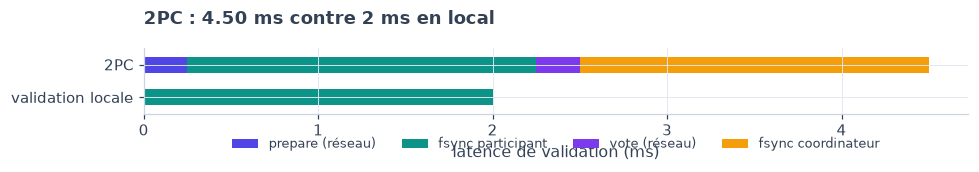

transactions en doute par an : 30 ; transactions-minutes bloquées : 150


In [2]:
run9 = run_2pc(latency=(0.25, 0.25), t_max=20, start_at=0.0, work_time=1.0,
               log_time=2.0, participant_kw=dict(prepare_time=2.0))
demande = 1.0
latence = run9.coord.decided_at - demande
verrous = (run9.summary["verrous_jusqu_à"] - demande).max()
print(f"latence de validation 2PC : {latence:.2f} ms (local : 2 ms)")
print(f"verrous tenus après la demande de validation : {verrous:.2f} ms")
comp = pd.DataFrame({"validation locale": [0, 2, 0, 0], "2PC": [0.25, 2, 0.25, 2]},
                    index=["prepare (réseau)", "fsync participant", "vote (réseau)", "fsync coordinateur"])
ax = comp.T.plot.barh(stacked=True, figsize=(9, 2.8), color=[INDIGO, TEAL, VIOLET, AMBER])
ax.set_xlabel("latence de validation (ms)")
ax.set_title(f"2PC : {comp['2PC'].sum():.2f} ms contre {comp['validation locale'].sum():.0f} ms en local")
ax.legend(fontsize=8.5, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.75))
plt.tight_layout(); plt.show()
print(f"transactions en doute par an : {12 * 1000 * 0.0025:.0f} ; transactions-minutes bloquées : {12 * 1000 * 0.0025 * 5:.0f}")

La simulation retrouve 4,5 ms de latence et 4,75 ms de détention des verrous.

> **À retenir.** 2PC double au moins la latence de validation (deux `fsync` séquentiels et
> un aller-retour de plus) et allonge d'autant la détention des verrous ; les pannes du
> coordinateur, même rares, laissent régulièrement des transactions en doute.

## Exercice 8.10 : injection exhaustive de pannes

**Énoncé.**

1. Faire tomber le coordinateur à l'instant $t_c$ **et** le participant `db1` à
   l'instant $t_p$, pour toutes les paires sur une grille de 0,2 à 7,8 (pas de 0,4),
   chacun redémarrant 6 unités plus tard. Vérifier que la transaction est toujours
   atomique et toujours terminée à la fin de la simulation. Représenter la durée maximale
   de détention des verrous.
2. Même expérience avec la validation naïve en une phase et une panne du seul
   participant : quelle fraction des instants de panne viole l'atomicité ?

**Rappels.** Abandon unilatéral avant le vote, participant en doute après, abandon
présumé au redémarrage du coordinateur (cours 5, sections 3 et 4).

**Solution.** On s'attend à 100 % d'exécutions atomiques et terminées avec 2PC : le
participant qui tombe avant de voter annule à son redémarrage (et vote non si on le lui
demande), celui qui tombe après avoir voté relit son vote et interroge le coordinateur ;
le coordinateur relit sa décision ou présume l'abandon. Avec la validation en une phase,
un participant qui tombe avant de recevoir `commit` annule à son redémarrage pendant que
l'autre valide : l'atomicité est perdue chaque fois que la panne survient entre le début
du travail et la réception de `commit`.

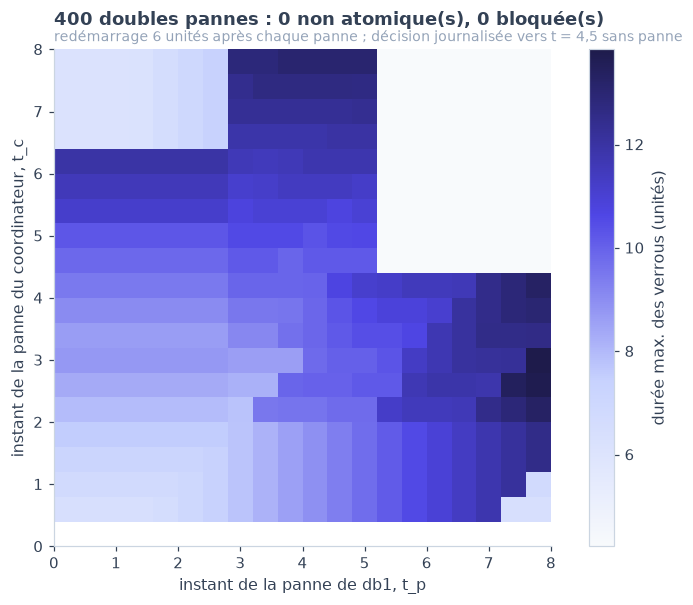

In [3]:
grille = np.round(np.arange(0.2, 8.0, 0.4), 2)
M = np.zeros((len(grille), len(grille)))
non_atomique, non_termine = 0, 0
for i, tc in enumerate(grille):
    for j, tp in enumerate(grille):
        r = run_2pc(crash={"coord": (tc, tc + 6), "db1": (tp, tp + 6)}, t_max=60)
        non_atomique += not r.atomic
        non_termine += "en doute" in set(r.summary["issue"])
        M[i, j] = r.summary["durée_verrous"].max()
fig, ax = plt.subplots(figsize=(7.5, 5.6))
im = ax.imshow(M, origin="lower", cmap="ddia_seq", extent=[grille[0] - 0.2, grille[-1] + 0.2, grille[0] - 0.2, grille[-1] + 0.2])
plt.colorbar(im, ax=ax, label="durée max. des verrous (unités)")
ax.grid(False)
ax.set_xlabel("instant de la panne de db1, t_p")
ax.set_ylabel("instant de la panne du coordinateur, t_c")
ax.set_title(f"{len(grille) ** 2} doubles pannes : {non_atomique} non atomique(s), {non_termine} bloquée(s)")
subtitle(ax, "redémarrage 6 unités après chaque panne ; décision journalisée vers t = 4,5 sans panne")
plt.tight_layout(); plt.show()

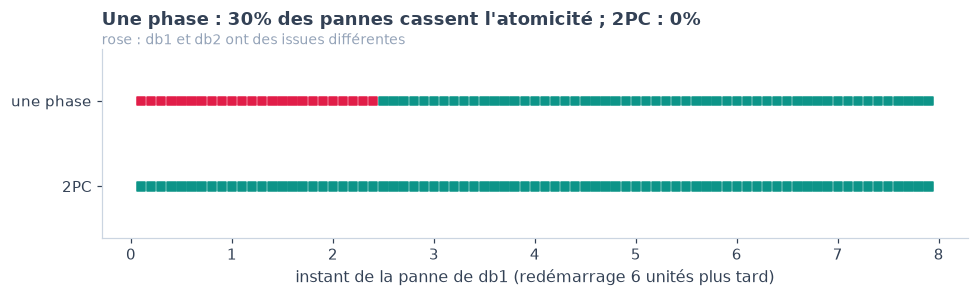

In [4]:
instants = np.round(np.arange(0.1, 8.0, 0.1), 2)
viol_1pc = [not run_2pc(protocol="1pc", crash={"db1": (t, t + 6)}, t_max=40).atomic for t in instants]
viol_2pc = [not run_2pc(crash={"db1": (t, t + 6)}, t_max=40).atomic for t in instants]
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.scatter(instants, np.ones_like(instants), c=[ROSE if v else TEAL for v in viol_1pc], s=30, marker="s")
ax.scatter(instants, np.zeros_like(instants), c=[ROSE if v else TEAL for v in viol_2pc], s=30, marker="s")
ax.set_yticks([0, 1]); ax.set_yticklabels(["2PC", "une phase"])
ax.set_ylim(-0.6, 1.6)
ax.grid(False)
ax.set_xlabel("instant de la panne de db1 (redémarrage 6 unités plus tard)")
ax.set_title(f"Une phase : {np.mean(viol_1pc):.0%} des pannes cassent l'atomicité ; 2PC : {np.mean(viol_2pc):.0%}")
subtitle(ax, "rose : db1 et db2 ont des issues différentes")
plt.tight_layout(); plt.show()

Avec 2PC, les 400 doubles pannes donnent toutes une transaction atomique et terminée ; la
carte montre le prix : quand le coordinateur tombe pendant la phase de préparation, ou
quand db1 tombe après avoir voté, les verrous restent tenus jusqu'aux redémarrages (zones
sombres). Avec la validation en une phase, toute panne de db1 entre la réception de
`begin` et celle de `commit` casse l'atomicité.

> **À retenir.** L'injection exhaustive de pannes est le bon réflexe pour tester un
> protocole : 2PC passe toutes les combinaisons (au prix de verrous tenus longtemps), la
> validation naïve échoue dès qu'un participant tombe au mauvais moment.

## Exercice 8.11 : un protocole de terminaison coopératif

**Énoncé.** Pour réduire le blocage, on autorise un participant en doute à interroger
**les autres participants** (et pas seulement le coordinateur).

1. Quelles réponses d'un autre participant permettent de décider sans risque ? Dans quel
   cas le blocage demeure-t-il ?
2. Implémenter ce protocole et mesurer, pour une panne **définitive** du coordinateur à
   l'instant $t$, la fraction des exécutions qui restent bloquées (au moins un participant
   en doute à la fin), avec et sans coopération (3 participants, 10 graines par instant,
   réseau qui perd 15 % des messages : sans pertes, tous les participants reçoivent
   `prepare` et la décision au même moment, et la coopération n'a rien à apprendre).

**Rappels.** Promesse du vote oui ; un participant qui n'a pas encore voté peut toujours
annuler (cours 5, sections 3 à 5).

**Solution.**

*1.* Un participant P en doute demande à Q :

- Q connaît la décision (commit ou abort) : P l'adopte. C'est sûr, la décision était
  unique.
- Q **n'a pas encore voté** : Q peut annuler unilatéralement (il n'a rien promis) ; il
  annule et le dit. Le coordinateur ne pourra jamais obtenir l'unanimité : la décision ne
  peut être que abort, P annule aussi.
- Q est **lui-même en doute** (il a voté oui sans connaître la décision) : aucune
  information. Si **tous** les participants sont dans ce cas, ils ne peuvent pas savoir si
  le coordinateur a décidé commit avant de tomber : le blocage demeure. C'est le cœur du
  problème, que seul un consensus résout (le coordinateur doit être répliqué).

Attention à une course : Q reçoit `prepare`, commence à écrire son vote, et reçoit la
question de P avant d'avoir fini. S'il annule, il doit ensuite voter **non** (et non oui).

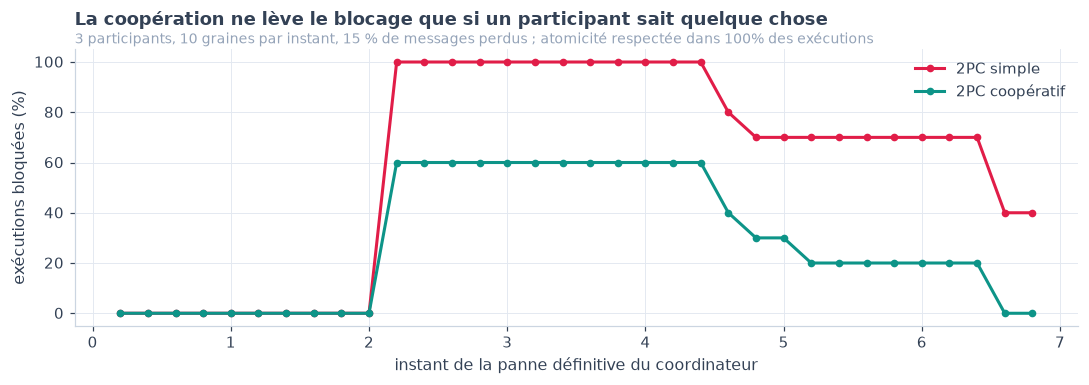

In [5]:
class Cooperatif(Participant2PC):
    pairs: list = []

    def _query(self):
        if self.state == "prepared" and self.outcome is None:
            self.send(self.coordinator, ("status?",))
            for p in self.pairs:
                if p != self.name:
                    self.send(p, ("pair?",))
            self.timer(self.query_interval, self._query)

    def _prepared(self, src):
        if self.outcome == "abort":         # a annulé entre-temps : il doit voter non
            self.send(src, ("vote", "no"))
            return
        super()._prepared(src)

    def on_message(self, src, msg):
        if msg[0] == "pair?":
            if self.outcome is not None:
                self.send(src, ("status", self.outcome))
            elif self.state in ("idle", "working"):
                self._decide("abort")       # pas encore de promesse : on peut annuler
                self.send(src, ("status", "abort"))
            # en doute : pas de réponse utile
        else:
            super().on_message(src, msg)


def lance(cls, t_panne, seed, n=3, t_max=40, drop=0.15):
    net = Network(seed=seed, latency=(0.3, 1.2), drop=drop)
    noms = [f"db{i + 1}" for i in range(n)]
    coord = net.add(Coordinator2PC("coord", noms))
    parts = []
    for nom in noms:
        p = cls(nom, unilateral_timeout=8.0)     # avant le vote, on peut abandonner seul
        p.pairs = noms
        parts.append(net.add(p))
    net.at(t_panne, net.crash, "coord")
    net.run(until=t_max)
    bloque = any(p.prepared_at is not None and p.outcome is None for p in parts)
    decided = {p.outcome for p in parts if p.outcome is not None}
    return dict(bloqué=bloque, atomique=len(decided) <= 1)


instants = np.round(np.arange(0.2, 7.0, 0.2), 2)
lignes = []
for t in instants:
    for nom, cls in [("2PC simple", Participant2PC), ("2PC coopératif", Cooperatif)]:
        rs = [lance(cls, t, s) for s in range(10)]
        lignes.append(dict(t=t, protocole=nom, bloqué=np.mean([r["bloqué"] for r in rs]),
                           atomique=np.mean([r["atomique"] for r in rs])))
coop = pd.DataFrame(lignes)
fig, ax = plt.subplots(figsize=(10, 3.6))
for nom, c in [("2PC simple", ROSE), ("2PC coopératif", TEAL)]:
    g_ = coop[coop["protocole"] == nom]
    ax.plot(g_["t"], g_["bloqué"] * 100, marker="o", ms=4, color=c, label=nom)
ax.set_xlabel("instant de la panne définitive du coordinateur")
ax.set_ylabel("exécutions bloquées (%)")
ax.set_title("La coopération ne lève le blocage que si un participant sait quelque chose")
subtitle(ax, f"3 participants, 10 graines par instant, 15 % de messages perdus ; atomicité respectée dans {coop['atomique'].mean():.0%} des exécutions")
ax.legend()
plt.tight_layout(); plt.show()

Lecture :

- panne **avant la préparation** ($t < 2$) : personne n'a voté ; chaque participant
  annule seul à l'expiration de son délai, personne n'est bloqué ;
- panne **pendant la préparation** : sans coopération, tout participant qui a voté oui
  reste bloqué (100 %) ; avec coopération, il suffit qu'un `prepare` se soit perdu (le
  participant concerné n'a pas voté, il annule et le dit) pour débloquer tout le monde ;
  restent bloqués les cas (60 %) où tous ont reçu `prepare` et voté oui ;
- panne **après la décision** : sans coopération, quiconque a perdu le message de décision
  reste bloqué (le coordinateur ne peut plus le renvoyer) ; avec coopération, ceux qui
  l'ont reçue la transmettent ; restent bloqués les cas où **personne** ne l'a reçue ;
- l'atomicité est respectée dans 100 % des exécutions : la coopération ne prend aucune
  décision risquée.

> **À retenir.** Interroger les pairs réduit le blocage de 2PC mais ne le supprime pas :
> quand tous les participants ont promis et que seul le coordinateur connaît la décision,
> il faut l'attendre, ou le répliquer par consensus.

## Exercice 8.12 : « exactement une fois » par déduplication

**Énoncé.** On reprend le traitement de messages du cours 5 (section 10).

1. Pourquoi l'identifiant du message doit-il être inséré **dans la même transaction** que
   les effets du message ?
2. Un développeur supprime l'identifiant **juste après la validation**, avant
   d'acquitter le message (« pour ne pas laisser traîner de données »). Quel scénario de
   panne produit alors un doublon ? Le vérifier.
3. Sans nettoyage, combien d'espace occupe la table des identifiants pour 10 000 messages
   par seconde, des identifiants de 16 octets et environ 40 octets de surcoût par ligne
   d'index, au bout d'un jour ? Et avec nettoyage après acquittement, si 0,1 % des
   traitements tombent en panne entre l'acquittement et le nettoyage ?

**Rappels.** Étapes 1 à 4 de la section *Exactly-Once Message Processing Revisited* ;
idempotence ; contrainte d'unicité (cours 5, section 10).

**Solution.**

*1.* Si l'identifiant était inséré dans une transaction séparée, une panne entre les deux
laisserait soit l'effet sans l'identifiant (le message, relivré, serait appliqué deux
fois), soit l'identifiant sans l'effet (le message, relivré, serait ignoré : perdu).
L'atomicité locale lie les deux : « effet appliqué » si et seulement si « identifiant
enregistré ».

*2.* Panne après la validation et la suppression, avant l'acquittement : le courtier
relivre le message, la table ne contient plus son identifiant, l'effet est appliqué une
seconde fois. L'identifiant ne doit disparaître qu'une fois **certain** que le courtier ne
relivrera plus le message, c'est-à-dire après l'acquittement.

*3.* Sans nettoyage : $10^4 \times 86\,400 \times 56 \approx 48$ Go par jour, sans limite.
Avec nettoyage après acquittement, seuls restent les identifiants des pannes entre
acquittement et nettoyage : $0{,}1\,\% \times 8{,}64 \cdot 10^8 = 864\,000$ lignes
(environ 48 Mo par jour), qu'un balayage périodique peut supprimer (ces messages ont été
acquittés).

In [6]:
def traite_suppression_precoce(conn, broker, msg, crash_at=None):
    """Variante fautive : l'identifiant est supprimé avant l'acquittement."""
    msg_id, montant = msg
    conn.execute("BEGIN")
    if conn.execute("SELECT 1 FROM processed WHERE msg_id = ?", (msg_id,)).fetchone():
        conn.execute("COMMIT")
        broker.ack(msg_id)
        return "doublon"
    conn.execute("INSERT INTO processed VALUES (?)", (msg_id,))
    conn.execute("UPDATE account SET balance = balance + ? WHERE id = 1", (montant,))
    if crash_at == "avant_commit":
        conn.execute("ROLLBACK")
        raise eo.Crash(crash_at)
    conn.execute("COMMIT")
    conn.execute("DELETE FROM processed WHERE msg_id = ?", (msg_id,))   # trop tôt !
    if crash_at == "avant_ack":
        raise eo.Crash(crash_at)
    broker.ack(msg_id)
    return "appliqué"


lignes = []
for nom, fonction in [("suppression après l'acquittement (correct)",
                       lambda c, b, m, p: eo.handle(c, b, m, "dedup", p)),
                      ("suppression avant l'acquittement (fautif)", traite_suppression_precoce)]:
    for panne in [None, "avant_commit", "avant_ack"]:
        conn, broker = eo.make_db(), eo.Broker([("m1", 10)])
        try:
            fonction(conn, broker, broker.next(), panne)
        except eo.Crash:
            pass
        m = broker.next()
        if m is not None:
            fonction(conn, broker, m, None)
        solde = conn.execute("SELECT balance FROM account").fetchone()[0]
        lignes.append(dict(variante=nom, panne=panne or "aucune", livraisons=broker.deliveries, solde=solde,
                           exactement_une_fois=solde == 10))
res12 = pd.DataFrame(lignes)
res12

,variante,panne,livraisons,solde,exactement_une_fois
0,suppression après l'acquittement (correct),aucune,1,10,True
1,suppression après l'acquittement (correct),avant_commit,2,10,True
2,suppression après l'acquittement (correct),avant_ack,2,10,True
3,suppression avant l'acquittement (fautif),aucune,1,10,True
4,suppression avant l'acquittement (fautif),avant_commit,2,10,True
5,suppression avant l'acquittement (fautif),avant_ack,2,20,False


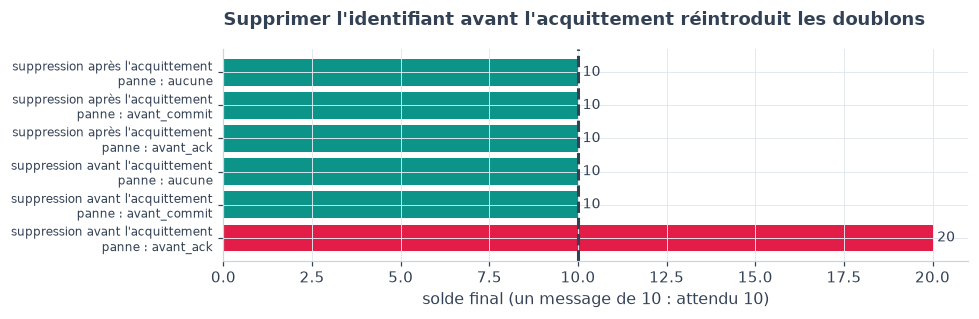

sans nettoyage : 48 Go/jour ; avec nettoyage : 864 000 lignes/jour


In [7]:
fig, ax = plt.subplots(figsize=(9, 3))
etiq = [f"{v.split(' (')[0]}\npanne : {p}" for v, p in zip(res12["variante"], res12["panne"])]
ax.barh(etiq, res12["solde"], color=[TEAL if ok else ROSE for ok in res12["exactement_une_fois"]])
ax.axvline(10, color=SLATE, ls="--")
annotate_bars(ax, "{:.0f}")
ax.invert_yaxis()
ax.tick_params(axis="y", labelsize=8)
ax.set_xlabel("solde final (un message de 10 : attendu 10)")
ax.set_title("Supprimer l'identifiant avant l'acquittement réintroduit les doublons")
plt.tight_layout(); plt.show()
print(f"sans nettoyage : {1e4 * 86400 * 56 / 1e9:.0f} Go/jour ; avec nettoyage : "
      f"{0.001 * 1e4 * 86400:,.0f} lignes/jour".replace(",", " "))

La variante fautive compte le message deux fois quand la panne survient entre la
validation et l'acquittement ; la version correcte ne se trompe jamais.

> **À retenir.** L'idempotence par identifiant repose sur deux règles d'ordre :
> identifiant et effets dans la **même** transaction ; suppression de l'identifiant
> seulement **après** l'acquittement.